# Bab 8: Tree-Based Algorithms and Ensemble Methods

Notebook ini merangkum Bab 8 buku *scikit-learn Cookbook* (Third Edition) karya John Sukup. Tidak semua algoritma machine learning menuntut matematika yang rumit. Model berbasis tree adalah contohnya: ia membagi data secara rekursif berdasarkan nilai fitur, lalu membuat prediksi dari pembagian itu. Di praktik, tree sering digabung menjadi **ensemble** untuk performa yang lebih baik.

Isi notebook:

1. Pengantar decision tree
2. Random forest dan bagging
3. Gradient boosting machine (GBM)
4. Tuning hyperparameter untuk tree dan ensemble
5. Membandingkan metode ensemble (bagging, boosting, stacking)
6. Latihan praktik

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              StackingClassifier, BaggingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

pd.set_option("display.precision", 4)


def styled_report(y_true, y_pred, **kwargs):
    """Classification report sebagai DataFrame berwarna."""
    rep = pd.DataFrame(classification_report(y_true, y_pred, output_dict=True, **kwargs)).transpose()
    return (rep.style
            .background_gradient(cmap="Blues", subset=["precision", "recall", "f1-score"])
            .format({"precision": "{:.3f}", "recall": "{:.3f}",
                     "f1-score": "{:.3f}", "support": "{:.0f}"}))


iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

## 1. Introduction to Decision Trees

Decision tree dipakai untuk klasifikasi maupun regresi. Cara kerjanya: data dibagi berulang berdasarkan nilai fitur, membentuk struktur seperti pohon. Setiap **internal node** adalah keputusan berdasarkan satu fitur, **cabang** (edge) adalah hasil keputusan itu, dan **leaf node** adalah prediksi akhir.

Tree populer karena mudah ditafsirkan dan bisa menangani data numerik maupun kategorikal. Walaupun mudah dipahami, tree sering mengalahkan model yang lebih rumit, jadi jangan diremehkan.

Mari mulai dengan `DecisionTreeClassifier` berargumen bawaan.

In [2]:
clf = DecisionTreeClassifier(random_state=2024)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.3f}")
display(styled_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.867


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.714,0.833,0.769,12
virginica,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


Model sudah cukup bagus walaupun memakai hyperparameter bawaan.

### Cara Kerja

Tree membagi dataset berdasarkan nilai fitur, dengan tujuan membuat tiap subkelompok lebih **homogen**. Kriteria split yang umum adalah **Gini impurity** (bawaan scikit-learn) atau **entropy**.

Kita bisa memvisualisasikan tree untuk memahami bagaimana split dibuat.

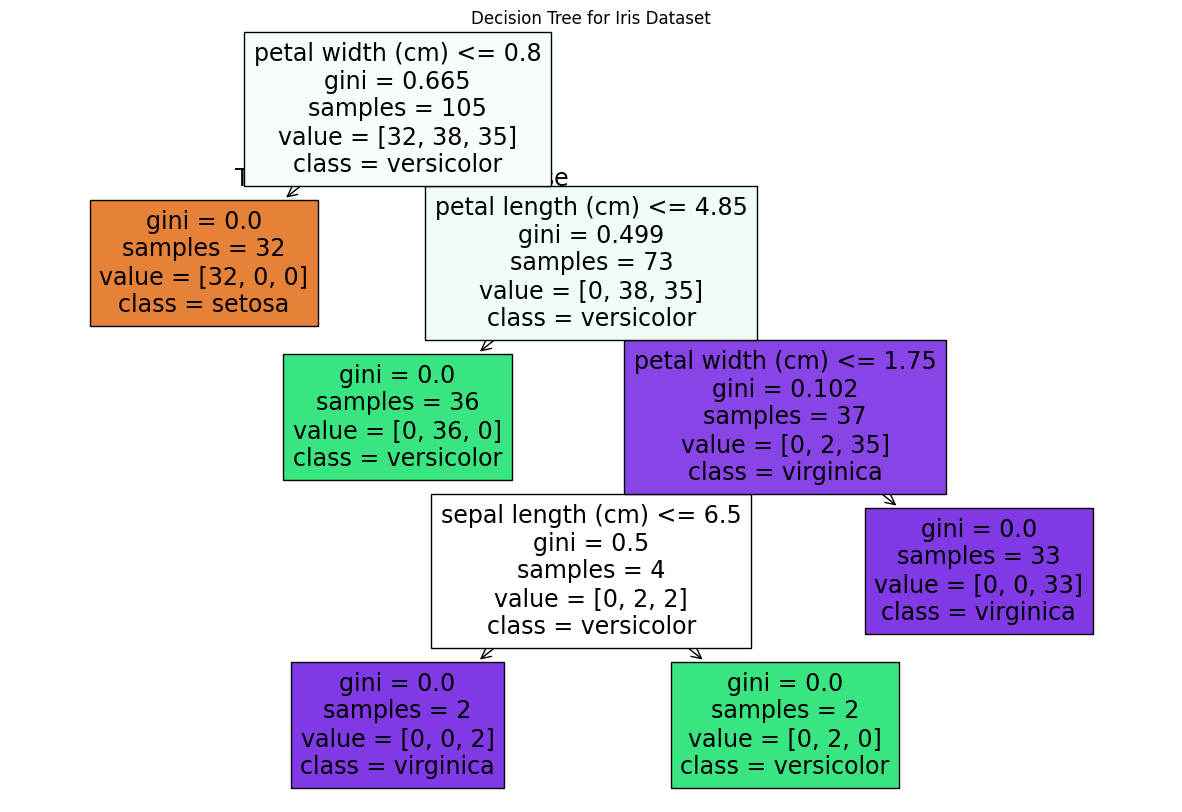

In [3]:
plt.figure(figsize=(15, 10))
plot_tree(clf, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True)
plt.title("Decision Tree for Iris Dataset")
plt.show()

Cara membaca tiap node pada gambar:

- **Nama fitur dan ambang**: node paling atas (root) berisi aturan seperti `petal width (cm) <= 0.8`. Jika kondisi benar, ikuti cabang kiri (True). Jika salah, ikuti cabang kanan (False). Ketika sampai di node tanpa cabang lagi (terminal atau leaf), data diberi kelas yang proporsinya terbesar di node itu. Contoh: iris dengan lebar petal 0.8 cm atau kurang berakhir di leaf kelas setosa.
- **Gini**: ukuran kemurnian node. Nilai 0.0 berarti node murni (hanya satu kelas), nilai makin tinggi berarti kelasnya makin tercampur. Split dipilih untuk menurunkan nilai ini.
- **Samples**: jumlah (atau proporsi) data latih yang masuk ke node itu. Di root, 100% data, lalu berkurang ke bawah.
- **Value**: jumlah data tiap kelas di node tersebut.
- **Class**: kelas dominan di node. Kalau node itu leaf, inilah prediksinya.

### Mengendalikan Kompleksitas Tree

Tree yang dibiarkan tumbuh akan overfitting. Beberapa hyperparameter pengendalinya:

- `max_depth`: jumlah level split maksimum. Makin dalam, makin kompleks. Ini trade-off antara kompleksitas dan kemurnian node.
- `min_samples_split`: node dengan sampel kurang dari nilai ini tidak akan dipecah lagi.
- `min_samples_leaf`: jumlah sampel minimum di setiap leaf. Split yang menghasilkan leaf lebih kecil dari ini tidak dilakukan.
- `max_features`: batas jumlah fitur yang dipertimbangkan pada tiap split. Bawaannya `None`, artinya semua fitur dipakai.
- `min_impurity_decrease`: split hanya dibuat kalau penurunan impurity mencapai nilai ini.

In [4]:
# Contoh: tree yang dibatasi kompleksitasnya
clf_small = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=2024)
clf_small.fit(X_train, y_train)

print(f"Akurasi latih: {clf_small.score(X_train, y_train):.3f}")
print(f"Akurasi uji  : {clf_small.score(X_test, y_test):.3f}")

# Bandingkan dengan tree penuh
print(f"\nTree penuh -> latih: {clf.score(X_train, y_train):.3f}, uji: {clf.score(X_test, y_test):.3f}")

Akurasi latih: 0.981
Akurasi uji  : 0.889

Tree penuh -> latih: 1.000, uji: 0.867


Tree penuh biasanya mencapai akurasi latih sempurna (1.0), tetapi akurasi ujinya tidak ikut naik. Selisih seperti ini adalah tanda overfitting.

## 2. Random Forests and Bagging

Satu decision tree mudah dipahami, tetapi di dunia nyata biasanya hanya dipakai sebagai bagian dari ensemble karena kelemahannya, terutama overfitting. Seperti kata pepatah, dua kepala (atau di sini, pohon) lebih baik daripada satu.

**Random forest** menggabungkan banyak decision tree untuk meningkatkan akurasi dan mengurangi overfitting. Idenya memakai **bootstrap aggregating (bagging)**: tiap tree dilatih pada sampel data yang diambil dengan pengembalian. Prediksi akhir adalah suara mayoritas (klasifikasi) atau rata-rata (regresi).

In [5]:
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
rf_clf.fit(X_train, y_train)

y_pred_rf = rf_clf.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.3f}")
display(styled_report(y_test, y_pred_rf, target_names=iris.target_names))

Accuracy: 0.911


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.833,0.833,0.833,12
virginica,0.867,0.867,0.867,15
accuracy,0.911,0.911,0.911,1
macro avg,0.900,0.900,0.900,45
weighted avg,0.911,0.911,0.911,45


Di contoh buku, accuracy satu decision tree adalah 0.867 sementara random forest 0.911. Peningkatan ini berasal dari penggabungan banyak model (angka persis bisa sedikit berbeda tergantung versi library dan seed).

### Cara Kerja

Random forest membangun banyak tree dari sampel bootstrap. Selain itu, di setiap split hanya sebagian fitur yang dipilih acak sebagai kandidat. Keragaman ini menurunkan variansi dan membuat model lebih stabil pada data baru.

Kita juga bisa melihat fitur mana yang paling berkontribusi lewat **feature importance**.

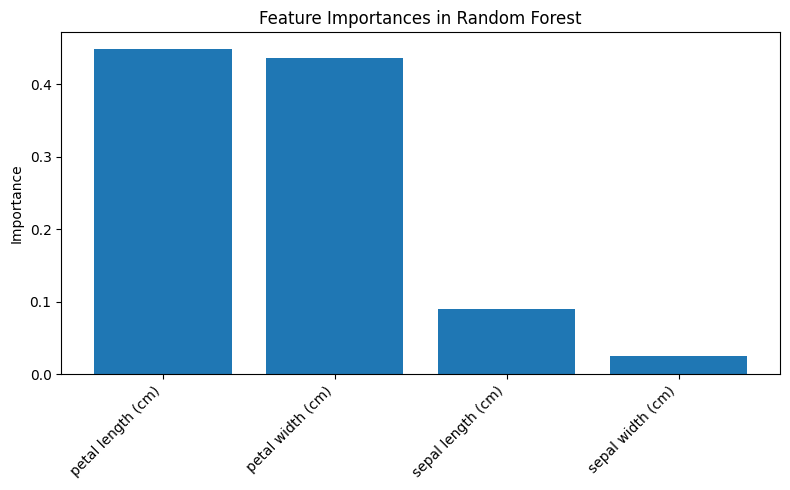

In [6]:
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8, 5))
plt.title("Feature Importances in Random Forest")
plt.bar(range(X.shape[1]), importances[indices], align="center")
plt.xticks(range(X.shape[1]), [iris.feature_names[i] for i in indices], rotation=45, ha="right")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

Petal length dan petal width mendominasi, sesuai dengan pengamatan di bab sebelumnya. Kadang random forest dipakai hanya untuk seleksi fitur: fitur terpenting dipilih lalu diteruskan ke algoritma lain.

Hyperparameter yang biasa disetel: `n_estimators`, `max_features`, dan `max_depth`. Konsep bagging juga bisa dipakai untuk model lain lewat `BaggingClassifier()` dan `BaggingRegressor()`.

In [7]:
# Bagging pada model lain: contoh dengan decision tree sebagai base estimator
bag_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=2024),
    n_estimators=100, random_state=2024)
bag_clf.fit(X_train, y_train)
print(f"Bagging accuracy: {bag_clf.score(X_test, y_test):.3f}")

Bagging accuracy: 0.889


## 3. Gradient Boosting Machines

**Gradient boosting machine (GBM)** membangun dan menggabungkan model-model lemah (biasanya tree dangkal) secara **berurutan**. Berbeda dengan random forest yang membuat tree secara paralel dan independen, GBM menambahkan satu tree pada satu waktu, dan tiap tree baru berusaha meminimalkan kesalahan model sebelumnya. Dari situ muncul istilah *boosting*: performa ditingkatkan bertahap.

In [8]:
gbm_clf = GradientBoostingClassifier(
    n_estimators=1000, learning_rate=0.2, random_state=2024)
gbm_clf.fit(X_train, y_train)

y_pred_gbm = gbm_clf.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred_gbm):.3f}")
display(styled_report(y_test, y_pred_gbm, target_names=iris.target_names))

Accuracy: 0.867


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.714,0.833,0.769,12
virginica,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


Di contoh buku, hasil GBM ini sama dengan decision tunggal. Itu bisa berarti keduanya sudah mencapai batas performa pada data ini, atau sama-sama overfitting (1000 tree dengan learning rate 0.2 cukup agresif). Bagian tuning berikutnya membahas hal tersebut.

### Cara Kerja

GBM bekerja secara iteratif. Dimulai dari prediksi awal yang sederhana, tiap tree berikutnya dilatih untuk memprediksi **residual** (selisih antara nilai sebenarnya dan prediksi saat itu). Tiap iterasi memperkecil kesalahan sehingga model perlahan menangkap pola yang kompleks.

### Hal yang Perlu Diperhatikan

Hyperparameter seperti `learning_rate`, `max_depth`, dan `n_estimators` sangat memengaruhi performa. Dua teknik pendukung:

- **Early stopping**: menghentikan proses training lebih awal untuk menghindari overfitting. Pada tree biasa, tanpa batasan, tree akan tumbuh sampai tiap sampel latih masuk ke leaf sendiri-sendiri, yang jelas overfit. Membatasi hyperparameter berfungsi serupa.
- **Validation curve**: grafik pengaruh perubahan hyperparameter terhadap metrik, diukur pada data latih dan uji. Kalau skor rendah di keduanya, model underfitting. Kalau skor latih tinggi tapi validasi rendah, model overfitting.

Berikut cara memantau kurva performa GBM per jumlah tree dengan `staged_predict`.

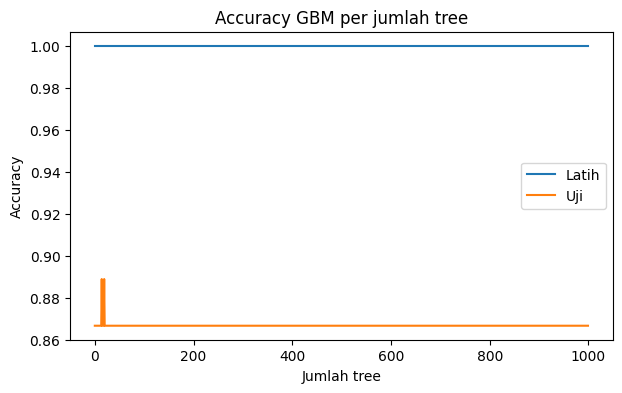

In [9]:
train_acc, test_acc = [], []
for pred_tr, pred_te in zip(gbm_clf.staged_predict(X_train), gbm_clf.staged_predict(X_test)):
    train_acc.append(accuracy_score(y_train, pred_tr))
    test_acc.append(accuracy_score(y_test, pred_te))

plt.figure(figsize=(7, 4))
plt.plot(train_acc, label="Latih")
plt.plot(test_acc, label="Uji")
plt.xlabel("Jumlah tree")
plt.ylabel("Accuracy")
plt.title("Accuracy GBM per jumlah tree")
plt.legend()
plt.show()

## 4. Hyperparameter Tuning for Trees and Ensembles

Tuning hyperparameter penting untuk decision tree, random forest, dan GBM. Alatnya sama dengan bab sebelumnya, yaitu grid search dan cross-validation. Yang berbeda hanya hyperparameter-nya: kedalaman tree, jumlah estimator, dan learning rate.

In [10]:
param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.1, 0.2],
}

grid_search = GridSearchCV(
    GradientBoostingClassifier(random_state=2024),
    param_grid, cv=5, scoring="accuracy")
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV score  : {grid_search.best_score_:.3f}")

Best Parameters: {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}
Best CV score  : 0.981


In [11]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
display(styled_report(y_test, y_pred, target_names=iris.target_names))

Test accuracy: 0.867


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.714,0.833,0.769,12
virginica,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


Grid search mencoba semua kombinasi hyperparameter, dan kombinasi dengan skor cross-validation terbaik dipilih. Cross-validation memberi estimasi performa yang lebih andal karena tiap konfigurasi dinilai pada beberapa pembagian data, mensimulasikan variasi yang akan dihadapi model di dunia nyata.

Ada alternatif lain, `RandomizedSearchCV()`, yang mencoba kombinasi hyperparameter acak. Kadang cara ini justru lebih cepat dan lebih baik dari grid search, terutama kalau ruang parameternya besar.

### Visualisasi Hasil Tuning

Heatmap berikut menunjukkan rata-rata skor cross-validation untuk kombinasi `max_depth` dan `n_estimators`.

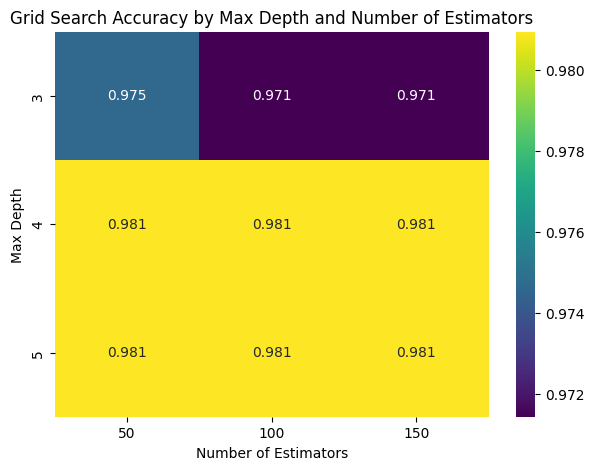

In [12]:
results = pd.DataFrame(grid_search.cv_results_)
pivot_table = results.pivot_table(
    values="mean_test_score",
    index="param_max_depth",
    columns="param_n_estimators")

plt.figure(figsize=(7, 5))
sns.heatmap(pivot_table, annot=True, fmt=".3f", cmap="viridis")
plt.title("Grid Search Accuracy by Max Depth and Number of Estimators")
plt.xlabel("Number of Estimators")
plt.ylabel("Max Depth")
plt.show()

Heatmap ini memperlihatkan bagaimana akurasi berubah di antara kombinasi hyperparameter. Di contoh buku, setelah `max_depth` dan `n_estimators` melewati kira-kira 4 dan 50, akurasi tidak membaik lagi. Perhatikan bahwa tiap sel merata-ratakan nilai `learning_rate`.

## 5. Comparing Ensemble Methods

Membandingkan metode ensemble membantu kita memahami kekuatan dan kelemahannya:

- **Bagging** (misalnya random forest): merata-ratakan prediksi banyak tree dari sampel bootstrap, terutama mengurangi variansi.
- **Boosting** (misalnya GBM): membangun model berurutan untuk memperbaiki kesalahan model sebelumnya, terutama mengurangi bias.
- **Stacking**: menggabungkan beberapa model dasar lewat model meta (final estimator) yang belajar cara terbaik mengombinasikan prediksi mereka.

Hasil terbaik bergantung pada masalahnya, jadi cara paling jujur adalah mencobanya pada data kita sendiri.

In [13]:
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
gb_clf = GradientBoostingClassifier(n_estimators=100, random_state=2024)
stacking_clf = StackingClassifier(
    estimators=[("rf", rf_clf), ("gb", gb_clf)],
    final_estimator=LogisticRegression(),
    cv=5)

rf_clf.fit(X_train, y_train)
gb_clf.fit(X_train, y_train)
stacking_clf.fit(X_train, y_train)

rf_accuracy = accuracy_score(y_test, rf_clf.predict(X_test))
gb_accuracy = accuracy_score(y_test, gb_clf.predict(X_test))
stacking_accuracy = accuracy_score(y_test, stacking_clf.predict(X_test))

print(f"Random Forest Accuracy:     {rf_accuracy:.2f}")
print(f"Gradient Boosting Accuracy: {gb_accuracy:.2f}")
print(f"Stacking Accuracy:          {stacking_accuracy:.2f}")

Random Forest Accuracy:     0.91
Gradient Boosting Accuracy: 0.87
Stacking Accuracy:          0.87


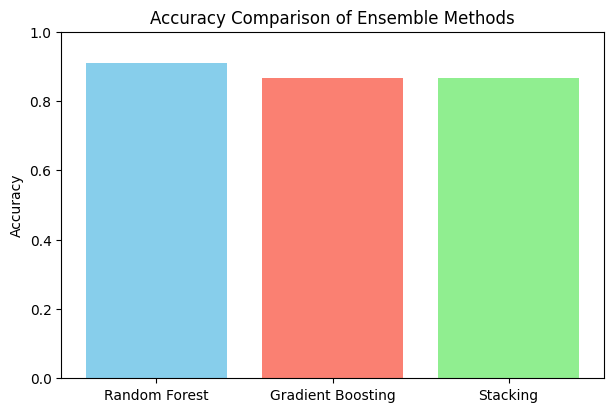

In [14]:
methods = ["Random Forest", "Gradient Boosting", "Stacking"]
accuracies = [rf_accuracy, gb_accuracy, stacking_accuracy]

plt.figure(figsize=(7, 4.5))
plt.bar(methods, accuracies, color=["skyblue", "salmon", "lightgreen"])
plt.title("Accuracy Comparison of Ensemble Methods")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

Di contoh buku, random forest unggul (sekitar 0.91) dibanding GBM dan stacking (sekitar 0.87). Perbedaannya kecil dan datasetnya kecil, jadi jangan terlalu cepat menyimpulkan bahwa satu metode selalu lebih baik. Untuk gambaran lebih adil, bandingkan di beberapa dataset dan dengan metrik tambahan seperti precision, recall, F1, atau ROC. Bisa juga memakai cross-validation, bukan satu kali split saja.

In [15]:
# Perbandingan yang lebih stabil dengan cross-validation
from sklearn.model_selection import cross_val_score

for name, model in [("Random Forest", rf_clf), ("Gradient Boosting", gb_clf), ("Stacking", stacking_clf)]:
    scores = cross_val_score(model, X, y, cv=5)
    print(f"{name:<18} mean={scores.mean():.3f}  std={scores.std():.3f}")

Random Forest      mean=0.960  std=0.025
Gradient Boosting  mean=0.960  std=0.033
Stacking           mean=0.967  std=0.021


## 6. Practical Exercises with Tree-Based Models

### Latihan 1: Membangun dan Mengevaluasi Decision Tree Classifier

In [16]:
X_tr, X_te, y_tr, y_te = train_test_split(iris.data, iris.target, test_size=0.3, random_state=2024)

tree = DecisionTreeClassifier(max_depth=4, random_state=2024).fit(X_tr, y_tr)
pred = tree.predict(X_te)

print(f"Accuracy: {accuracy_score(y_te, pred):.3f}")
print(classification_report(y_te, pred, target_names=iris.target_names))

Accuracy: 0.867
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        18
  versicolor       0.71      0.83      0.77        12
   virginica       0.85      0.73      0.79        15

    accuracy                           0.87        45
   macro avg       0.85      0.86      0.85        45
weighted avg       0.87      0.87      0.87        45



### Latihan 2: Hyperparameter Tuning pada Random Forest

In [17]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 3, 5],
    "max_features": ["sqrt", None],
    "min_samples_leaf": [1, 2, 4],
}

gs = GridSearchCV(RandomForestClassifier(random_state=2024), param_grid, cv=5, n_jobs=-1)
gs.fit(X_tr, y_tr)

print("Best params:", gs.best_params_)
print(f"Best CV score: {gs.best_score_:.3f}")

pred = gs.best_estimator_.predict(X_te)
print(f"Test accuracy: {accuracy_score(y_te, pred):.3f}")

Best params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV score: 0.971
Test accuracy: 0.911


### Latihan 3: Membandingkan Gradient Boosting dan Random Forest

In [18]:
rf = RandomForestClassifier(n_estimators=100, random_state=2024).fit(X_tr, y_tr)
gb = GradientBoostingClassifier(n_estimators=100, random_state=2024).fit(X_tr, y_tr)

for name, m in [("Random Forest", rf), ("Gradient Boosting", gb)]:
    pred = m.predict(X_te)
    print(f"=== {name} (accuracy {accuracy_score(y_te, pred):.3f}) ===")
    print(classification_report(y_te, pred, target_names=iris.target_names))

=== Random Forest (accuracy 0.911) ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        18
  versicolor       0.83      0.83      0.83        12
   virginica       0.87      0.87      0.87        15

    accuracy                           0.91        45
   macro avg       0.90      0.90      0.90        45
weighted avg       0.91      0.91      0.91        45

=== Gradient Boosting (accuracy 0.867) ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        18
  versicolor       0.71      0.83      0.77        12
   virginica       0.85      0.73      0.79        15

    accuracy                           0.87        45
   macro avg       0.85      0.86      0.85        45
weighted avg       0.87      0.87      0.87        45



## Poin-poin Penting Bab 8

- Decision tree membagi data secara rekursif berdasarkan fitur. Ia mudah ditafsirkan, tetapi cenderung overfitting jika dibiarkan tumbuh. `max_depth`, `min_samples_split`, `min_samples_leaf`, dan `min_impurity_decrease` membatasi kompleksitasnya.
- Random forest menggabungkan banyak tree dari sampel bootstrap (bagging) dengan sampling acak fitur pada tiap split. Hasilnya lebih stabil, dan `feature_importances_` membantu menafsirkan model.
- Gradient boosting membangun tree berurutan, tiap tree memperbaiki residual model sebelumnya. Learning rate, kedalaman, dan jumlah tree harus disetel dengan hati-hati agar tidak overfitting.
- Grid search dengan cross-validation (atau `RandomizedSearchCV`) menemukan kombinasi hyperparameter terbaik.
- Bagging menurunkan variansi, boosting menurunkan bias, dan stacking menggabungkan beberapa model lewat model meta. Metode terbaik bergantung pada data, jadi bandingkan dengan cross-validation.

Referensi: Sukup, J. (2025). *scikit-learn Cookbook*, Third Edition, Bab 8 "Tree-Based Algorithms and Ensemble Methods". Packt Publishing.